# Quiz 1：準備資料集 / Dataset

**蘇芯儀 / Sharon0726**

本 Notebook 附已執行的結果；完整訓練程式見 `run_experiments.py`。

In [1]:
# 子目標：定位作業目錄，讀取已完成的真實實驗結果。
from pathlib import Path
import csv, json
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / "results" / "metrics.json").exists():
    raise FileNotFoundError("請在 Week3 作業目錄開啟 Notebook。")
R = ROOT / "results"
metrics = json.loads((R / "metrics.json").read_text())
selected = json.loads((R / "selection.json").read_text())["selected"]
classes = json.loads((R / "classes.json").read_text())
def table(rows, columns):
    text = "| " + " | ".join(columns) + " |\n| " + " | ".join(["---"]*len(columns)) + " |\n"
    for row in rows:
        text += "| " + " | ".join(str(row[c]) for c in columns) + " |\n"
    display(Markdown(text))
def figure(name):
    display(Image(filename=str(R / "figures" / name)))


## Quiz 1：準備資料集（15 分）

### 來源與分類任務

使用 [CIFAR-10 官方資料集](https://www.cs.toronto.edu/~kriz/cifar.html)（Krizhevsky, 2009），包含 60,000 張 32×32 RGB 影像、10 個互斥類別。官方分成 50,000 training images 與 10,000 test images，原始壓縮檔透過 TorchVision 下載並以其內建 checksum 驗證。

問題定義為 **single-label, 10-class image classification**：給定一張 RGB 影像，輸出 10 類 logits／softmax 機率，以最大分數的類別為 Top-1 預測。

| ID | Class | 繁體中文 |
|---|---|---|
| 0 | airplane | 飛機 |
| 1 | automobile | 汽車 |
| 2 | bird | 鳥 |
| 3 | cat | 貓 |
| 4 | deer | 鹿 |
| 5 | dog | 狗 |
| 6 | frog | 青蛙 |
| 7 | horse | 馬 |
| 8 | ship | 船 |
| 9 | truck | 卡車 |

### 固定切分與資料洩漏控制

對官方 50,000 張 training images 依類別分層，以 NumPy RNG seed **20260923** 打亂各類索引；每類取 4,500 train、500 validation。官方 test 完整保留。

| Split | 每類 | 總數 | 來源與用途 |
|---|---:|---:|---|
| Train | 4,500 | 45,000 | 官方 train；計算梯度與更新權重 |
| Validation | 500 | 5,000 | 官方 train；選 learning rate、epoch 與 baseline／augmentation |
| Test | 1,000 | 10,000 | 官方 test；決策鎖定後才做最終推論 |

使用全部 60,000 張影像；train／validation 沒有重複索引。test 的 index 屬於另一個官方檔案，因此數值相同不表示是同一張圖。`split_manifest.csv` 同時記錄 source 與 index，可完整稽核。採單次固定 validation split，未採可選的 K-Fold。所有實驗共用這組 split。

影像先轉為 [0,1]，再使用固定的 ImageNet mean=(0.485,0.456,0.406)、std=(0.229,0.224,0.225) 正規化；沒有由 validation／test 估計統計量。Plain CNN 保持 32×32；ResNet 用 bilinear、antialias=True 放大為 64×64。評估均為單一確定性視角，不做隨機擴增或 test-time augmentation。



In [2]:
# 子目標：驗證來源索引完整涵蓋，且 train／validation 沒有交集。
split = np.load(R / "split_indices.npz")
assert not set(split["train"]) & set(split["validation"])
assert np.array_equal(np.sort(np.concatenate([split["train"], split["validation"], split["unused"]])), np.arange(50000))
with (R / "split_manifest.csv").open(encoding="utf-8") as f:
    manifest = list(csv.DictReader(f))
rows = [{"class": cls, **{s: sum(row["split"] == s and int(row["label"]) == c for row in manifest)
         for s in ["train", "validation", "test", "unused"]}} for c, cls in enumerate(classes)]
table(rows, ["class", "train", "validation", "test", "unused"])
print("Split integrity: passed; official train and test use separate index namespaces.")

| class | train | validation | test | unused |
| --- | --- | --- | --- | --- |
| airplane | 4500 | 500 | 1000 | 0 |
| automobile | 4500 | 500 | 1000 | 0 |
| bird | 4500 | 500 | 1000 | 0 |
| cat | 4500 | 500 | 1000 | 0 |
| deer | 4500 | 500 | 1000 | 0 |
| dog | 4500 | 500 | 1000 | 0 |
| frog | 4500 | 500 | 1000 | 0 |
| horse | 4500 | 500 | 1000 | 0 |
| ship | 4500 | 500 | 1000 | 0 |
| truck | 4500 | 500 | 1000 | 0 |


Split integrity: passed; official train and test use separate index namespaces.


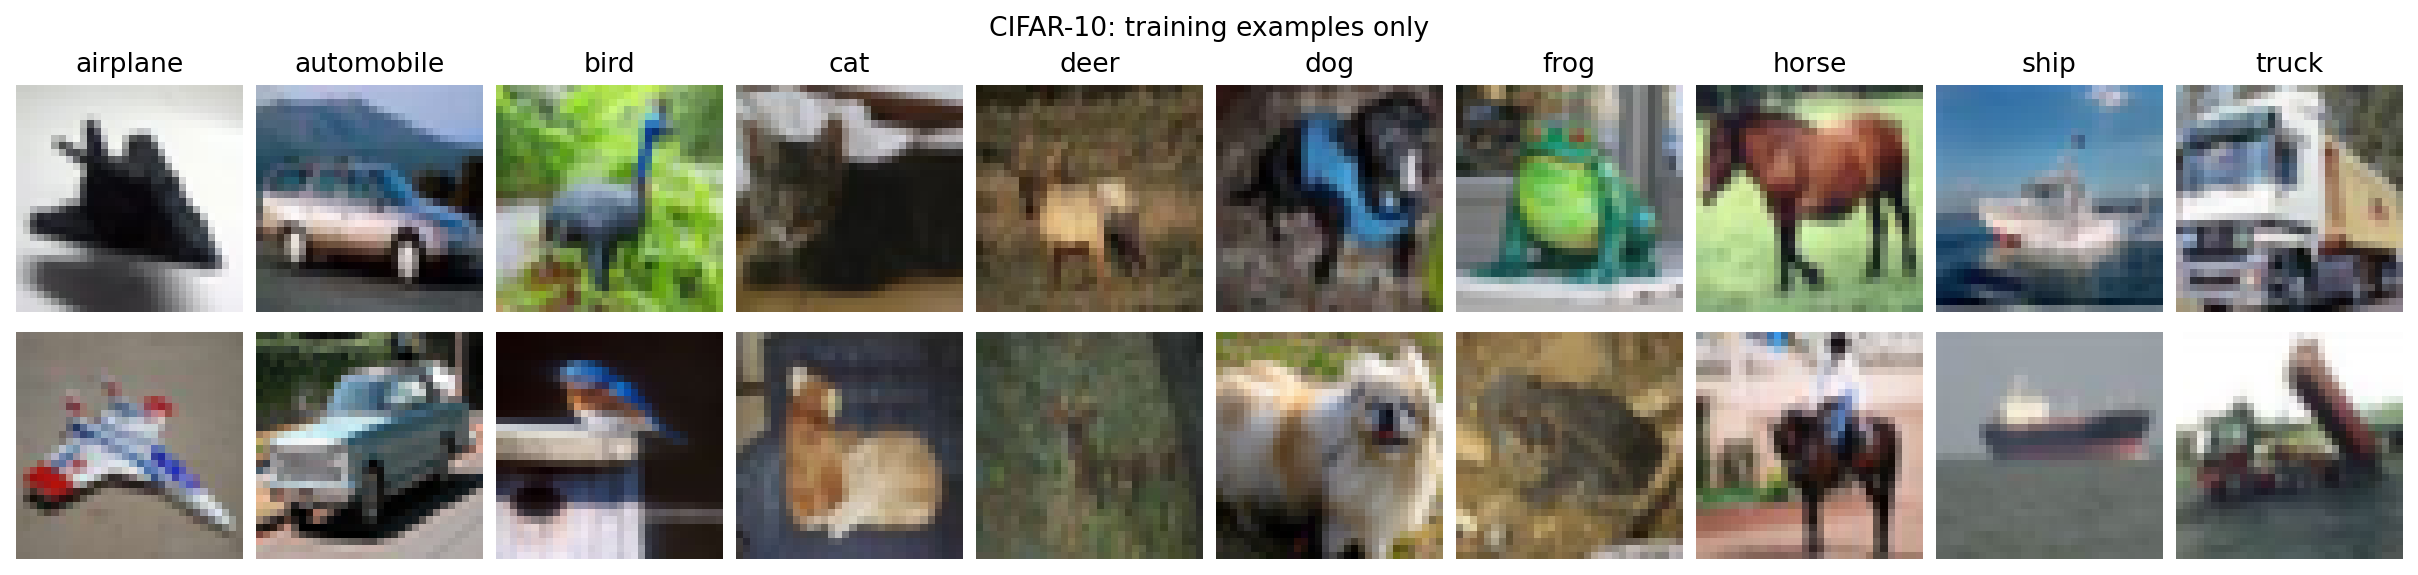

In [3]:
# 子目標：展示每類的訓練影像。
figure("dataset_samples.png")

### 執行整份實驗

於本目錄執行 `python run_experiments.py`；資料將由 TorchVision 下載並核對 checksum。原始影像不存入 Git。